<a href="https://colab.research.google.com/github/GHseyram/Ghana-energy-transition-investment-analytics/blob/main/notebooks/03_solar_investment_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ghana Solar Investment Model
## Illustrative Commercial and Industrial Solar Analysis

Author: Seyram Amedede

### Purpose
Estimate annual electricity generation, electricity-bill savings
and simple payback for an illustrative solar installation.

### Approach
State assumptions explicitly and compare scenarios for installation
cost, solar yield and the value of electricity savings.

### Scope
This is an educational scenario model. Its initial inputs are
illustrative assumptions, not verified Ghana market quotations.
Simple payback excludes financing, taxes, discounting and changes
in performance over time.

In [1]:
import pandas as pd

# Illustrative assumptions — not verified market data.
# All monetary values are in US dollars (USD).
system_size_kwp = 100
installation_cost_per_kwp = 900
annual_yield_kwh_per_kwp = 1500
self_consumption_rate = 0.90
avoided_electricity_cost_per_kwh = 0.15
annual_maintenance_rate = 0.015

assumptions = pd.DataFrame({
    "Assumption": [
        "Solar system size",
        "Installation cost",
        "Annual solar yield",
        "Share of generation used on site",
        "Avoided electricity cost",
        "Annual maintenance as share of installation cost"
    ],
    "Value": [
        system_size_kwp,
        installation_cost_per_kwp,
        annual_yield_kwh_per_kwp,
        self_consumption_rate,
        avoided_electricity_cost_per_kwh,
        annual_maintenance_rate
    ],
    "Unit": [
        "kWp",
        "USD/kWp",
        "kWh/kWp/year",
        "fraction (0.90 = 90%)",
        "USD/kWh",
        "fraction (0.015 = 1.5%)"
    ]
})

assumptions

,Assumption,Value,Unit
0,Solar system size,100.000,kWp
1,Installation cost,900.000,USD/kWp
2,Annual solar yield,1500.000,kWh/kWp/year
3,Share of generation used on site,0.900,fraction (0.90 = 90%)
4,Avoided electricity cost,0.150,USD/kWh
5,Annual maintenance as share of installation cost,0.015,fraction (0.015 = 1.5%)


In [2]:
installation_cost = system_size_kwp * installation_cost_per_kwp

annual_generation = system_size_kwp * annual_yield_kwh_per_kwp
annual_self_consumed_energy = annual_generation * self_consumption_rate

annual_bill_savings = (
    annual_self_consumed_energy * avoided_electricity_cost_per_kwh
)
annual_maintenance_cost = installation_cost * annual_maintenance_rate
annual_net_savings = annual_bill_savings - annual_maintenance_cost

simple_payback_years = (
    installation_cost / annual_net_savings
    if annual_net_savings > 0
    else float("inf")
)

print(f"Installation cost: USD {installation_cost:,.0f}")
print(f"Annual generation: {annual_generation:,.0f} kWh")
print(f"Annual energy used on site: {annual_self_consumed_energy:,.0f} kWh")
print(f"Annual electricity-bill savings: USD {annual_bill_savings:,.0f}")
print(f"Annual maintenance cost: USD {annual_maintenance_cost:,.0f}")
print(f"Annual net savings: USD {annual_net_savings:,.0f}")
print(f"Simple payback: {simple_payback_years:.2f} years")

Installation cost: USD 90,000
Annual generation: 150,000 kWh
Annual energy used on site: 135,000 kWh
Annual electricity-bill savings: USD 20,250
Annual maintenance cost: USD 1,350
Annual net savings: USD 18,900
Simple payback: 4.76 years


### Base-case results

Under the illustrative assumptions, a 100 kWp solar installation
costs USD 90,000 and generates 150,000 kWh annually.

With 90% of generation consumed on site, 135,000 kWh offsets
purchased electricity. At an assumed avoided electricity cost
of USD 0.15/kWh, annual bill savings equal USD 20,250.

After USD 1,350 in annual maintenance costs, annual net savings
are USD 18,900. The resulting simple payback is approximately
4.76 years.

This result depends on the stated assumptions. It does not establish
the financial viability of a specific Ghanaian project. The model
assumes constant annual generation, electricity value and maintenance
costs, and excludes financing, taxes, degradation, equipment
replacement and revenue from exported electricity.

In [3]:
scenario_inputs = [
    ("Conservative", 1100, 1300, 0.12),
    ("Base case", 900, 1500, 0.15),
    ("Optimistic", 750, 1700, 0.18)
]

results = []

for name, cost_per_kwp, yield_per_kwp, electricity_value in scenario_inputs:
    cost = system_size_kwp * cost_per_kwp
    generation = system_size_kwp * yield_per_kwp
    bill_savings = generation * self_consumption_rate * electricity_value
    maintenance = cost * annual_maintenance_rate
    net_savings = bill_savings - maintenance

    payback = cost / net_savings if net_savings > 0 else float("inf")

    results.append({
        "Scenario": name,
        "Cost (USD/kWp)": cost_per_kwp,
        "Yield (kWh/kWp/year)": yield_per_kwp,
        "Electricity value (USD/kWh)": electricity_value,
        "Installation cost (USD)": cost,
        "Annual net savings (USD)": net_savings,
        "Simple payback (years)": payback
    })

scenario_results = pd.DataFrame(results)
scenario_results.round(2)

,Scenario,Cost (USD/kWp),Yield (kWh/kWp/year),Electricity value (USD/kWh),Installation cost (USD),Annual net savings (USD),Simple payback (years)
0,Conservative,1100,1300,0.12,110000,12390.0,8.88
1,Base case,900,1500,0.15,90000,18900.0,4.76
2,Optimistic,750,1700,0.18,75000,26415.0,2.84


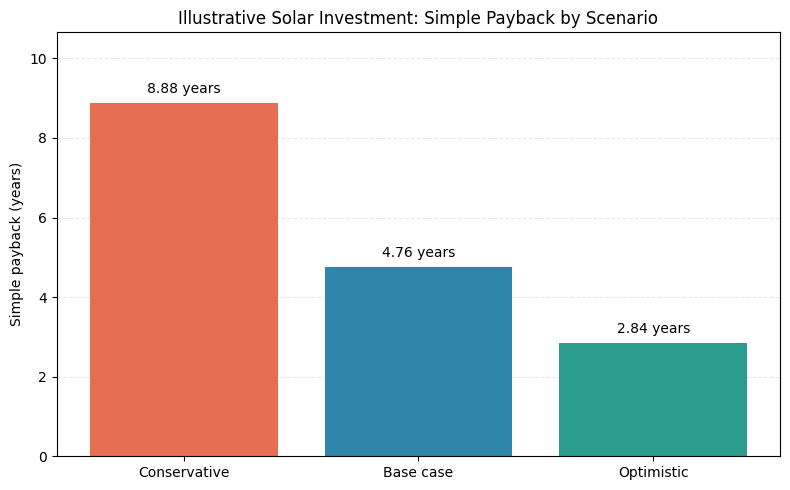

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    scenario_results["Scenario"],
    scenario_results["Simple payback (years)"],
    color=["#E76F51", "#2E86AB", "#2A9D8F"]
)

ax.bar_label(bars, fmt="%.2f years", padding=5)

ax.set_title("Illustrative Solar Investment: Simple Payback by Scenario")
ax.set_ylabel("Simple payback (years)")
ax.set_ylim(
    0,
    scenario_results["Simple payback (years)"].max() * 1.2
)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Scenario interpretation

Simple payback ranges from approximately 8.88 years in the
conservative scenario to 4.76 years in the base case and
2.84 years in the optimistic scenario.

Lower installation costs, higher solar generation and a higher
value of avoided electricity purchases shorten payback.
The system size, self-consumption rate and maintenance percentage
remain constant across these scenarios.

Because three inputs change together, this comparison does not
isolate the effect of any single input. The scenarios are illustrative
assumption sets, not forecasts or probabilities.

The next analysis will vary one input at a time while holding
the others at their base-case values.

In [5]:
electricity_values = [0.10, 0.12, 0.15, 0.18, 0.20]
sensitivity_results = []

for electricity_value in electricity_values:
    bill_savings = annual_self_consumed_energy * electricity_value
    net_savings = bill_savings - annual_maintenance_cost

    payback = (
        installation_cost / net_savings
        if net_savings > 0
        else float("inf")
    )

    sensitivity_results.append({
        "Electricity value (USD/kWh)": electricity_value,
        "Annual net savings (USD)": net_savings,
        "Simple payback (years)": payback
    })

electricity_sensitivity = pd.DataFrame(sensitivity_results)
electricity_sensitivity.round(2)

,Electricity value (USD/kWh),Annual net savings (USD),Simple payback (years)
0,0.10,12150.0,7.41
1,0.12,14850.0,6.06
2,0.15,18900.0,4.76
3,0.18,22950.0,3.92
4,0.20,25650.0,3.51


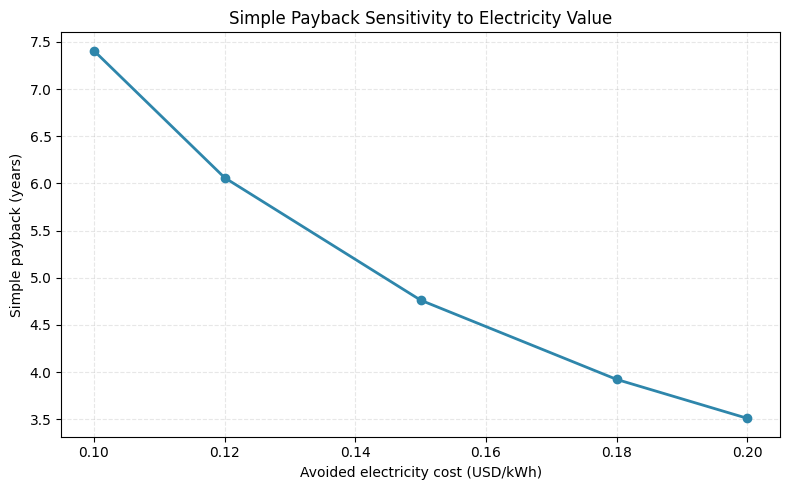

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    electricity_sensitivity["Electricity value (USD/kWh)"],
    electricity_sensitivity["Simple payback (years)"],
    marker="o",
    color="#2E86AB",
    linewidth=2
)

ax.set_title("Simple Payback Sensitivity to Electricity Value")
ax.set_xlabel("Avoided electricity cost (USD/kWh)")
ax.set_ylabel("Simple payback (years)")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Electricity-value sensitivity

Holding all other base-case assumptions constant, increasing the
avoided electricity cost from USD 0.10/kWh to USD 0.20/kWh reduces
simple payback from approximately 7.41 years to 3.51 years.

At USD 0.15/kWh, simple payback remains approximately 4.76 years,
matching the base case.

Solar electricity used on site creates greater bill savings when
it replaces more expensive purchased electricity. The relevant
value is the cost actually avoided per kWh, which may differ from
an average electricity tariff if some charges remain payable.

These electricity values are illustrative assumptions, not verified
Ghana tariffs. This analysis isolates electricity value; installation
cost, solar yield, self-consumption and maintenance remain fixed.

In [7]:
installation_cost_values = [700, 800, 900, 1000, 1100]
cost_results = []

for cost_per_kwp in installation_cost_values:
    cost = system_size_kwp * cost_per_kwp
    maintenance = cost * annual_maintenance_rate
    net_savings = annual_bill_savings - maintenance

    payback = cost / net_savings if net_savings > 0 else float("inf")

    cost_results.append({
        "Installation cost (USD/kWp)": cost_per_kwp,
        "Total installation cost (USD)": cost,
        "Annual maintenance (USD)": maintenance,
        "Annual net savings (USD)": net_savings,
        "Simple payback (years)": payback
    })

cost_sensitivity = pd.DataFrame(cost_results)
cost_sensitivity.round(2)

,Installation cost (USD/kWp),Total installation cost (USD),Annual maintenance (USD),Annual net savings (USD),Simple payback (years)
0,700,70000,1050.0,19200.0,3.65
1,800,80000,1200.0,19050.0,4.20
2,900,90000,1350.0,18900.0,4.76
3,1000,100000,1500.0,18750.0,5.33
4,1100,110000,1650.0,18600.0,5.91


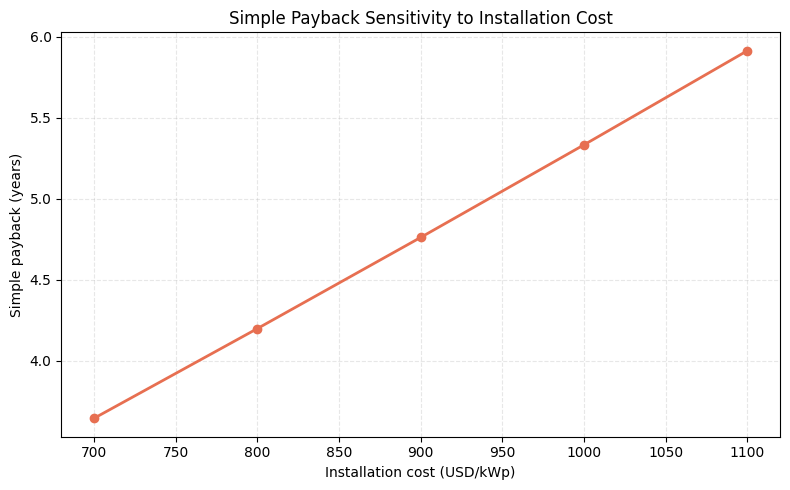

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    cost_sensitivity["Installation cost (USD/kWp)"],
    cost_sensitivity["Simple payback (years)"],
    marker="o",
    color="#E76F51",
    linewidth=2
)

ax.set_title("Simple Payback Sensitivity to Installation Cost")
ax.set_xlabel("Installation cost (USD/kWp)")
ax.set_ylabel("Simple payback (years)")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Installation-cost sensitivity

Holding solar yield, self-consumption and electricity value at
their base-case levels, increasing installation cost from
USD 700/kWp to USD 1,100/kWp increases simple payback from
approximately 3.65 years to 5.91 years.

At USD 900/kWp, simple payback is approximately 4.76 years,
matching the base case.

Higher installation costs increase the initial investment and
annual maintenance costs, because maintenance is modelled as
1.5% of installation cost. Annual electricity-bill savings
remain unchanged.

These costs are illustrative assumptions, not verified supplier
quotations. Comparing actual proposals would also require
assessing equipment quality, expected generation, warranties
and the scope of installation work.

In [9]:
solar_yield_values = [1300, 1400, 1500, 1600, 1700]
yield_results = []

for solar_yield in solar_yield_values:
    generation = system_size_kwp * solar_yield
    self_consumed_energy = generation * self_consumption_rate
    bill_savings = (
        self_consumed_energy * avoided_electricity_cost_per_kwh
    )
    net_savings = bill_savings - annual_maintenance_cost

    payback = (
        installation_cost / net_savings
        if net_savings > 0
        else float("inf")
    )

    yield_results.append({
        "Solar yield (kWh/kWp/year)": solar_yield,
        "Annual generation (kWh)": generation,
        "Annual net savings (USD)": net_savings,
        "Simple payback (years)": payback
    })

yield_sensitivity = pd.DataFrame(yield_results)
yield_sensitivity.round(2)

,Solar yield (kWh/kWp/year),Annual generation (kWh),Annual net savings (USD),Simple payback (years)
0,1300,130000,16200.0,5.56
1,1400,140000,17550.0,5.13
2,1500,150000,18900.0,4.76
3,1600,160000,20250.0,4.44
4,1700,170000,21600.0,4.17


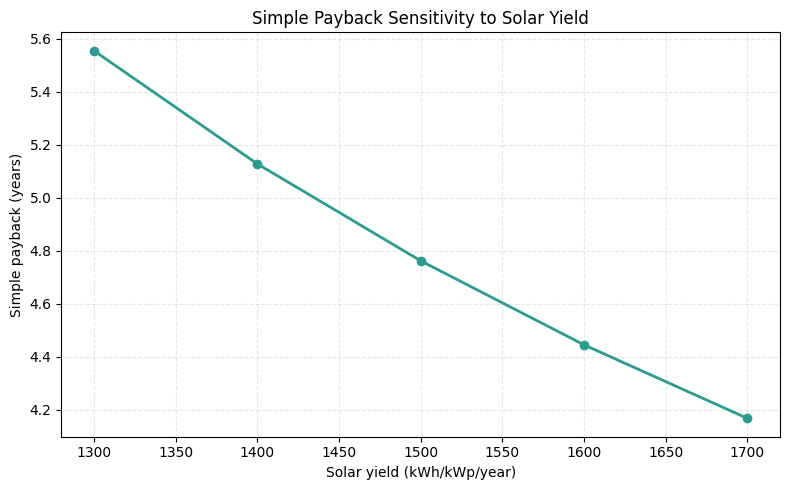

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    yield_sensitivity["Solar yield (kWh/kWp/year)"],
    yield_sensitivity["Simple payback (years)"],
    marker="o",
    color="#2A9D8F",
    linewidth=2
)

ax.set_title("Simple Payback Sensitivity to Solar Yield")
ax.set_xlabel("Solar yield (kWh/kWp/year)")
ax.set_ylabel("Simple payback (years)")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Solar-yield sensitivity

Holding all other base-case assumptions constant, increasing
annual solar yield from 1,300 to 1,700 kWh/kWp/year reduces
simple payback from approximately 5.56 years to 4.17 years.

At 1,500 kWh/kWp/year, simple payback remains approximately
4.76 years, matching the base case.

Higher solar yield increases electricity generation and bill
savings while installation and annual maintenance costs remain
fixed.

The model assumes 90% of generation is consumed on site at every
yield level. In practice, this proportion depends on how closely
solar generation matches the customer's electricity demand.

These yields are illustrative assumptions. A project assessment
would require a site-specific generation estimate accounting
for solar resources, shading, system design and losses.

In [11]:
sensitivity_summary = pd.DataFrame({
    "Input varied": [
        "Avoided electricity cost",
        "Installation cost",
        "Annual solar yield"
    ],
    "Range tested": [
        "USD 0.10–0.20/kWh",
        "USD 700–1,100/kWp",
        "1,300–1,700 kWh/kWp/year"
    ],
    "Shortest payback (years)": [
        electricity_sensitivity["Simple payback (years)"].min(),
        cost_sensitivity["Simple payback (years)"].min(),
        yield_sensitivity["Simple payback (years)"].min()
    ],
    "Longest payback (years)": [
        electricity_sensitivity["Simple payback (years)"].max(),
        cost_sensitivity["Simple payback (years)"].max(),
        yield_sensitivity["Simple payback (years)"].max()
    ]
})

sensitivity_summary.round(2)


,Input varied,Range tested,Shortest payback (years),Longest payback (years)
0,Avoided electricity cost,USD 0.10–0.20/kWh,3.51,7.41
1,Installation cost,"USD 700–1,100/kWp",3.65,5.91
2,Annual solar yield,"1,300–1,700 kWh/kWp/year",4.17,5.56


### Conclusion

The illustrative 100 kWp solar installation has an initial cost
of USD 90,000, annual net savings of USD 18,900 and a simple
payback of approximately 4.76 years under the base-case assumptions.

The sensitivity analyses show that higher avoided electricity
costs, lower installation costs and higher solar yields shorten
simple payback.

Each sensitivity analysis changes one input while holding the
remaining assumptions fixed. The tested ranges differ, so their
payback spreads should not be treated as a standardized ranking
of input importance.

### Limitations and next stage

The inputs are illustrative assumptions rather than verified
Ghana market data. The model excludes financing, taxes,
discounting, degradation, equipment replacement and export revenue.
It also assumes a constant 90% self-consumption rate.

The next stage will extend the model to annual cash flows and
net present value (NPV), making the timing of costs and savings
explicit.

In [12]:
# Illustrative assumptions for a constant-dollar USD model
project_lifetime_years = 20
annual_degradation_rate = 0.005  # Generation falls 0.5% each year
real_discount_rate = 0.08       # 8% real annual discount rate

cash_flow_assumptions = pd.DataFrame({
    "Assumption": [
        "Project lifetime",
        "Annual generation degradation",
        "Real discount rate"
    ],
    "Value": [
        project_lifetime_years,
        annual_degradation_rate,
        real_discount_rate
    ],
    "Unit": [
        "years",
        "fraction (0.005 = 0.5%)",
        "fraction (0.08 = 8%)"
    ]
})

cash_flow_assumptions

,Assumption,Value,Unit
0,Project lifetime,20.000,years
1,Annual generation degradation,0.005,fraction (0.005 = 0.5%)
2,Real discount rate,0.080,fraction (0.08 = 8%)


In [13]:
cash_flow_rows = [{
    "Year": 0,
    "Generation (kWh)": 0,
    "Bill savings (USD)": 0,
    "Maintenance (USD)": 0,
    "Net cash flow (USD)": -installation_cost,
    "Discounted cash flow (USD)": -installation_cost
}]

for year in range(1, project_lifetime_years + 1):
    generation = annual_generation * (
        (1 - annual_degradation_rate) ** (year - 1)
    )
    bill_savings = (
        generation
        * self_consumption_rate
        * avoided_electricity_cost_per_kwh
    )
    net_cash_flow = bill_savings - annual_maintenance_cost
    discounted_cash_flow = (
        net_cash_flow / (1 + real_discount_rate) ** year
    )

    cash_flow_rows.append({
        "Year": year,
        "Generation (kWh)": generation,
        "Bill savings (USD)": bill_savings,
        "Maintenance (USD)": annual_maintenance_cost,
        "Net cash flow (USD)": net_cash_flow,
        "Discounted cash flow (USD)": discounted_cash_flow
    })

cash_flows = pd.DataFrame(cash_flow_rows)

project_npv = cash_flows["Discounted cash flow (USD)"].sum()

print(f"Project NPV: USD {project_npv:,.2f}")
cash_flows.round(2)


Project NPV: USD 88,743.48


,Year,Generation (kWh),Bill savings (USD),Maintenance (USD),Net cash flow (USD),Discounted cash flow (USD)
0,0,0.00,0.00,0.0,-90000.00,-90000.00
1,1,150000.00,20250.00,1350.0,18900.00,17500.00
2,2,149250.00,20148.75,1350.0,18798.75,16116.90
3,3,148503.75,20048.01,1350.0,18698.01,14843.08
4,4,147761.23,19947.77,1350.0,18597.77,13669.91
5,5,147022.43,19848.03,1350.0,18498.03,12589.45
6,6,146287.31,19748.79,1350.0,18398.79,11594.36
7,7,145555.88,19650.04,1350.0,18300.04,10677.90
8,8,144828.10,19551.79,1350.0,18201.79,9833.86
9,9,144103.96,19454.03,1350.0,18104.03,9056.52


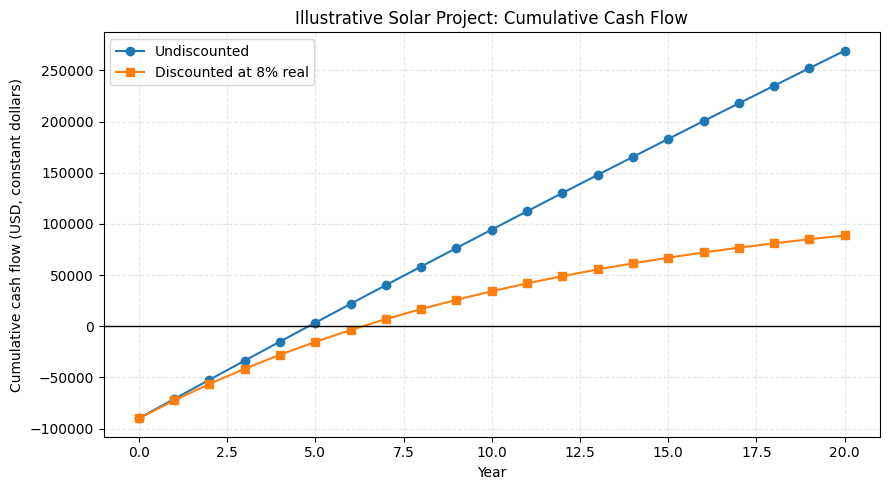

In [14]:
cash_flows["Cumulative cash flow (USD)"] = (
    cash_flows["Net cash flow (USD)"].cumsum()
)

cash_flows["Cumulative discounted cash flow (USD)"] = (
    cash_flows["Discounted cash flow (USD)"].cumsum()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    cash_flows["Year"],
    cash_flows["Cumulative cash flow (USD)"],
    label="Undiscounted",
    marker="o"
)

ax.plot(
    cash_flows["Year"],
    cash_flows["Cumulative discounted cash flow (USD)"],
    label="Discounted at 8% real",
    marker="s"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Illustrative Solar Project: Cumulative Cash Flow")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative cash flow (USD, constant dollars)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
def first_recovery_year(column):
    recovered = cash_flows.loc[
        cash_flows[column] >= 0, "Year"
    ]
    return int(recovered.iloc[0]) if not recovered.empty else None

recovery_year = first_recovery_year(
    "Cumulative cash flow (USD)"
)
discounted_recovery_year = first_recovery_year(
    "Cumulative discounted cash flow (USD)"
)

print(f"Project NPV: USD {project_npv:,.2f}")

print(
    "First year-end with investment recovered:",
    recovery_year if recovery_year is not None
    else "Not reached within project lifetime"
)

print(
    "First year-end with discounted investment recovered:",
    discounted_recovery_year if discounted_recovery_year is not None
    else "Not reached within project lifetime"
)


Project NPV: USD 88,743.48
First year-end with investment recovered: 5
First year-end with discounted investment recovered: 7


### Cash-flow and NPV interpretation

The model records the installation cost at year 0 and annual
electricity-bill savings minus maintenance at each subsequent
year-end. Generation declines by 0.5% annually after year 1.

Undiscounted cumulative cash flow shows when operating savings
recover the initial investment. Discounted cumulative cash flow
also accounts for the time value of money using an illustrative
8% real discount rate.

The final cumulative discounted cash flow equals the project NPV.
A positive NPV means the modelled cash flows exceed the initial
investment after discounting at the assumed rate. A negative NPV
means they fall short.

The recovery years reported above are the first whole year-end
at which cumulative cash flow becomes non-negative. They differ
from the earlier simple-payback estimate, which assumes constant
annual savings.

All cash flows are expressed in constant USD. These results depend
on illustrative assumptions and exclude financing, taxes, equipment
replacement, export revenue and residual value.

In [16]:
discount_rates = [0.04, 0.06, 0.08, 0.10, 0.12]
npv_results = []

for rate in discount_rates:
    discounted_flows = (
        cash_flows["Net cash flow (USD)"]
        / (1 + rate) ** cash_flows["Year"]
    )

    npv_results.append({
        "Real discount rate (%)": rate * 100,
        "Project NPV (USD)": discounted_flows.sum()
    })

npv_sensitivity = pd.DataFrame(npv_results)
npv_sensitivity.round(2)

,Real discount rate (%),Project NPV (USD)
0,4.0,155869.47
1,6.0,118180.96
2,8.0,88743.48
3,10.0,65431.38
4,12.0,46724.21


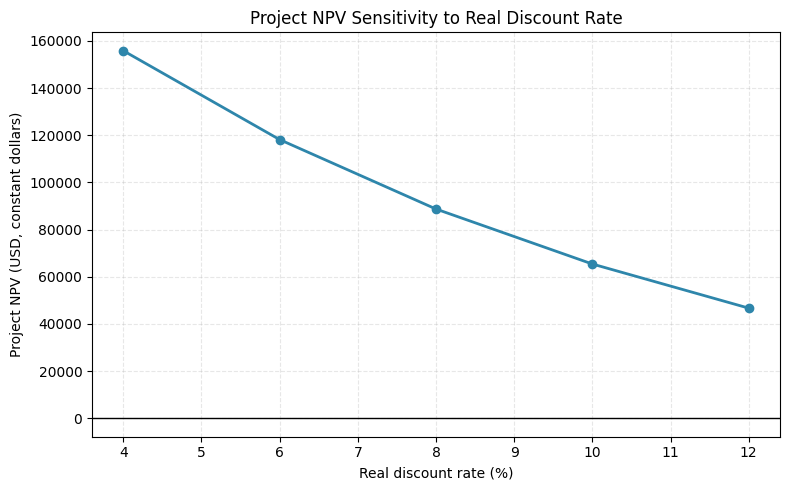

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    npv_sensitivity["Real discount rate (%)"],
    npv_sensitivity["Project NPV (USD)"],
    marker="o",
    color="#2E86AB",
    linewidth=2
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Project NPV Sensitivity to Real Discount Rate")
ax.set_xlabel("Real discount rate (%)")
ax.set_ylabel("Project NPV (USD, constant dollars)")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Discount-rate sensitivity

This analysis varies the real discount rate from 4% to 12% while
keeping the project's cash flows unchanged.

NPV decreases as the discount rate rises because future savings
receive less weight in today's money. The initial investment
occurs at year 0, so its value is unaffected by discounting.

The 8% result matches the base-case NPV calculation. A positive
NPV at a tested rate means the modelled cash flows exceed the
initial investment after discounting at that rate.

These rates are illustrative rather than estimates of an actual
investor's required return. Because cash flows are expressed in
constant USD, the analysis uses real discount rates.

### Summary of payback analysis

The illustrative 100 kWp solar installation has an initial cost
of USD 90,000, annual net savings of USD 18,900 in year 1 and
a simple payback of approximately 4.76 years.

Higher avoided electricity costs, lower installation costs and
higher solar yields shorten simple payback. Each sensitivity
analysis changes one input while holding the remaining assumptions
fixed. The different tested ranges do not provide a standardized
ranking of input importance.

### Extension to discounted cash flows

The following analysis extends the model to 20 years of annual
cash flows, incorporating 0.5% annual generation degradation
after year 1 and an illustrative 8% real discount rate.

It calculates NPV, identifies whole-year investment recovery
points and tests NPV sensitivity to real discount rates of
4% to 12%.

All inputs remain illustrative. The model excludes financing,
taxes, equipment replacement, export revenue and residual value.